# CaloDiffusion Photon Validation — Final Diagnostics and Closeout

## Purpose

This notebook completes the remaining **photon-only** diagnostics after native-cell ordering was verified.

It does **not** train or generate showers. It reads the three existing photon-run ZIP files and performs:

1. A controlled comparison of the five radial bins in the final active detector layer.
2. An event-level investigation of unusual radial, high-response and low-response showers.
3. A layer-by-layer comparison of those events with reference, generator and scale-only showers.
4. A final response-distribution comparison: mean, standard deviation, percentiles and Wasserstein distance, with bootstrap uncertainty.
5. A readiness summary showing what is complete and what remains a limitation before extending the same framework to electrons.

## Inputs

Upload these three ZIP files when prompted:

- Seed `20261020`: `validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip`
- Seed `20261021`: `validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip`
- Seed `20261022`: `validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip`

## Conventions

- The fixed reference is the 300-event reference sample from seed `20261020`, separately at each incident energy.
- All samples are analysed with the already-adopted photon cell threshold of **0.01 GeV (10 MeV)**. The model-generation settings are not changed.
- Each seed contributes 600 generated showers (two repeats of 300) and 300 scale-only showers per energy.
- Radial positions are in the XML geometry's units. The geometry metadata does not provide physical depth in this export, so depth plots use **active-layer ordinal**, not millimetres.
- Pooled results are descriptive. Seed-by-seed results are retained because there are only three seeds.

**Important limitation:** the manifests state `reference_is_unseen_by_checkpoint = false`. The data provenance relative to checkpoint training/selection is still unresolved. This notebook cannot establish an independent generalization benchmark.


## 0. Configure the analysis

The values below are fixed to the photon study. Do not change the cutoff merely to improve agreement.

In [1]:
import io
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from IPython.display import display

EXPECTED_SEEDS = [20261020, 20261021, 20261022]
REFERENCE_SEED = 20261020
ENERGIES_GEV = [8.192, 32.768, 65.536]
ANALYSIS_CUT_GEV = 0.01  # 10 MeV per native cell
N_BOOTSTRAP = 500
BOOTSTRAP_SEED = 20261104

OUTPUT_DIR = Path('/content/calo_photon_closeout')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Seeds:', EXPECTED_SEEDS)
print('Reference seed:', REFERENCE_SEED)
print('Energies (GeV):', ENERGIES_GEV)
print('Analysis threshold (GeV):', ANALYSIS_CUT_GEV)
print('Bootstrap repetitions:', N_BOOTSTRAP)

Seeds: [20261020, 20261021, 20261022]
Reference seed: 20261020
Energies (GeV): [8.192, 32.768, 65.536]
Analysis threshold (GeV): 0.01
Bootstrap repetitions: 500


## 1. Upload and load the three existing run ZIPs

Upload only the three photon fidelity ZIPs listed above. The code checks the seed in each manifest rather than trusting the uploaded filename.

In [2]:
from google.colab import files

uploaded = files.upload()
zip_uploads = {
    name: payload for name, payload in uploaded.items()
    if name.lower().endswith('.zip')
}

if len(zip_uploads) != 3:
    raise ValueError(
        f"Expected exactly 3 run ZIP files; received {len(zip_uploads)}. "
        "Upload the three photon ZIPs for seeds 20261020, 20261021 and 20261022."
    )

def unique_member(zf, suffix):
    matches = [name for name in zf.namelist() if name.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one archive member ending with {suffix!r}; "
            f"found {len(matches)}: {matches[:5]}"
        )
    return matches[0]

def read_json_member(zf, suffix):
    return json.loads(zf.read(unique_member(zf, suffix)).decode('utf-8'))

def read_npz_member(zf, suffix):
    with np.load(io.BytesIO(zf.read(unique_member(zf, suffix))), allow_pickle=False) as f:
        return {key: f[key].copy() for key in f.files}

runs = {}
for uploaded_name, payload in zip_uploads.items():
    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        manifest = read_json_member(zf, 'manifest.json')
        geometry = read_json_member(zf, 'photon_geometry.json')
        seed = int(manifest['config']['seed'])
        if seed in runs:
            raise ValueError(f'Duplicate seed {seed} was uploaded.')
        runs[seed] = {
            'manifest': manifest,
            'geometry': geometry,
            'data': {},
            'uploaded_name': uploaded_name,
        }
        for energy in ENERGIES_GEV:
            prefix = f'arrays/photon_{energy:.3f}GeV_'
            runs[seed]['data'][energy] = {
                'reference': read_npz_member(zf, prefix + 'reference_run-1.npz'),
                'generator_run0': read_npz_member(zf, prefix + 'generator_run0.npz'),
                'generator_run1': read_npz_member(zf, prefix + 'generator_run1.npz'),
                'scale_only': read_npz_member(zf, prefix + 'scale_only_run-1.npz'),
            }

if sorted(runs) != EXPECTED_SEEDS:
    raise ValueError(f'Expected seeds {EXPECTED_SEEDS}, loaded {sorted(runs)}.')

print('Loaded seeds:', sorted(runs))
for seed in sorted(runs):
    print(seed, '←', runs[seed]['uploaded_name'])

Saving validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip to validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip
Saving validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip to validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip
Saving validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip to validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip
Loaded seeds: [20261020, 20261021, 20261022]
20261020 ← validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip
20261021 ← validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip
20261022 ← validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip


## 2. Validate run compatibility and sample sizes

This checks whether the three runs used the same checkpoint, repository revision, reference file and photon geometry. It also confirms the expected number of showers. A passing compatibility check does **not** prove that the reference was unseen during training.

In [3]:
reference_hashes = set()
checkpoint_hashes = set()
revisions = set()
source_hash_sets = []
geometry_jsons = []
compatibility_rows = []

for seed in sorted(runs):
    m = runs[seed]['manifest']
    reference_hashes.add(m['reference_files']['photon']['sha256'])
    checkpoint_hashes.add(m['checkpoints']['photon']['sha256'])
    revisions.add(m['revision'])
    source_hash_sets.append(m['source_sha256'])
    geometry_jsons.append(runs[seed]['geometry'])
    compatibility_rows.append({
        'seed': seed,
        'revision': m['revision'],
        'checkpoint_sha256': m['checkpoints']['photon']['sha256'],
        'reference_sha256': m['reference_files']['photon']['sha256'],
        'reference_is_unseen_by_checkpoint': m.get('reference_is_unseen_by_checkpoint'),
        'analysis_cut_photon_GeV': m.get('analysis_cut_GeV_overrides', {}).get('photon'),
        'n_test': m['config']['n_test'],
        'generation_repeats': m['config']['generation_repeats'],
    })

assert len(reference_hashes) == 1, 'Reference HDF5 hashes differ across runs.'
assert len(checkpoint_hashes) == 1, 'Checkpoint hashes differ across runs.'
assert len(revisions) == 1, 'Repository revisions differ across runs.'
assert all(h == source_hash_sets[0] for h in source_hash_sets), 'Source hashes differ across runs.'
assert all(g == geometry_jsons[0] for g in geometry_jsons), 'Photon geometries differ across runs.'

compatibility_df = pd.DataFrame(compatibility_rows)
display(compatibility_df)

print('\nCompatibility checks passed.')
print('Common repository revision:', next(iter(revisions)))
print('Common reference file SHA256:', next(iter(reference_hashes)))
print('Common checkpoint SHA256:', next(iter(checkpoint_hashes)))
print('Reference unseen by checkpoint:', compatibility_df['reference_is_unseen_by_checkpoint'].unique())

if not compatibility_df['reference_is_unseen_by_checkpoint'].fillna(False).all():
    print('\nCAUTION: reference/checkpoint independence is NOT established.')

# Validate saved arrays and expected sample sizes.
for seed in sorted(runs):
    for energy in ENERGIES_GEV:
        d = runs[seed]['data'][energy]
        expected_shapes = {
            'reference': (300, 368),
            'generator_run0': (300, 368),
            'generator_run1': (300, 368),
            'scale_only': (300, 368),
        }
        for key, expected in expected_shapes.items():
            native = d[key]['native']
            assert native.shape == expected, (seed, energy, key, native.shape)
            assert np.isfinite(native).all(), (seed, energy, key, 'non-finite values')
            assert (native >= 0).all(), (seed, energy, key, 'negative physical cell value')
            e = np.asarray(d[key]['energy'], dtype=float)
            assert e.shape == (300,)
            assert np.allclose(e, energy, rtol=0, atol=1e-8), (seed, energy, key, e[:3])
            assert len(np.unique(d[key]['event_id'])) == 300, (seed, energy, key, 'duplicate event IDs')

print('\nPASS: all 3 seeds × 3 energies × 4 sample files have expected arrays.')

,seed,revision,checkpoint_sha256,reference_sha256,reference_is_unseen_by_checkpoint,analysis_cut_photon_GeV,n_test,generation_repeats
0,20261020,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,False,0.01,300,2
1,20261021,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,False,0.01,300,2
2,20261022,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,False,0.01,300,2



Compatibility checks passed.
Common repository revision: 00ebcc3534fc25eee0fe15361483833e0bca34e7
Common reference file SHA256: c8cd08f333d7d73c453cec39de6c5054de3a8940b63f3003de627645946fbacc
Common checkpoint SHA256: 0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd1580547118f77e1bee24
Reference unseen by checkpoint: [False]

CAUTION: reference/checkpoint independence is NOT established.

PASS: all 3 seeds × 3 energies × 4 sample files have expected arrays.


## 3. Reconstruct the already-verified native cell map

Native-cell ordering was checked in the preceding verification notebook. Here we reuse the same layer → angular-bin → radial-bin ordering to label the 368 saved cell values. This cell also checks the final-layer cell indices expected from the saved geometry.

In [4]:
geometry = runs[REFERENCE_SEED]['geometry']
layer_ids = list(map(int, geometry['layer_ids']))
n_angles = list(map(int, geometry['n_angles']))
radial_edges = [np.asarray(x, dtype=float) for x in geometry['radial_edges']]

cell_rows = []
layer_rows = []
offset = 0
for layer_ordinal, (layer_id, nang, edges) in enumerate(zip(layer_ids, n_angles, radial_edges)):
    nr = len(edges) - 1
    start = offset
    stop = start + nang * nr
    layer_rows.append({
        'layer_ordinal': layer_ordinal,
        'layer_id': layer_id,
        'n_angles': nang,
        'n_radial': nr,
        'native_start': start,
        'native_stop_exclusive': stop,
    })
    for angle in range(nang):
        for radial in range(nr):
            cell_rows.append({
                'native_index': offset + angle * nr + radial,
                'layer_ordinal': layer_ordinal,
                'layer_id': layer_id,
                'angle_index': angle,
                'radial_bin': radial,
                'r_low_XML': float(edges[radial]),
                'r_high_XML': float(edges[radial + 1]),
                'r_center_XML': float(0.5 * (edges[radial] + edges[radial + 1])),
            })
    offset = stop

cell_map = pd.DataFrame(cell_rows)
layer_map = pd.DataFrame(layer_rows)
assert offset == 368 and len(cell_map) == 368
assert layer_ids[-1] == 12 and layer_map.iloc[-1]['native_start'] == 363
assert layer_map.iloc[-1]['native_stop_exclusive'] == 368

final_layer_id = layer_ids[-1]
final_layer_cells = cell_map[cell_map['layer_id'] == final_layer_id].copy()
assert len(final_layer_cells) == 5
assert final_layer_cells['native_index'].tolist() == [363, 364, 365, 366, 367]
assert final_layer_cells['r_low_XML'].tolist() == [0.0, 100.0, 200.0, 400.0, 1000.0]
assert final_layer_cells['r_high_XML'].tolist() == [100.0, 200.0, 400.0, 1000.0, 2000.0]

print('Native cells:', len(cell_map))
print('Final active layer ID:', final_layer_id)
display(layer_map)
print('Final-layer radial bins:')
display(final_layer_cells[['native_index','radial_bin','r_low_XML','r_high_XML']])

Native cells: 368
Final active layer ID: 12


,layer_ordinal,layer_id,n_angles,n_radial,native_start,native_stop_exclusive
0,0,0,1,8,0,8
1,1,1,10,16,8,168
2,2,2,10,19,168,358
3,3,3,1,5,358,363
4,4,12,1,5,363,368


Final-layer radial bins:


,native_index,radial_bin,r_low_XML,r_high_XML
363,363,0,0.0,100.0
364,364,1,100.0,200.0
365,365,2,200.0,400.0
366,366,3,400.0,1000.0
367,367,4,1000.0,2000.0


## 4. Define the common 10 MeV analysis convention and event observables

The cutoff is applied cell-by-cell to **all** reference, generator and scale-only samples. We calculate response, energy in each active layer, final-layer fraction, outermost-cell energy and an energy-weighted radial RMS using XML radial-bin centres. The RMS is a geometry-based diagnostic in XML radial units, not a physical length in mm.

In [5]:
def apply_cell_cut(native, cut_gev=ANALYSIS_CUT_GEV):
    native = np.asarray(native, dtype=float)
    return np.where(native >= cut_gev, native, 0.0)

layer_cell_indices = {
    int(row.layer_id): cell_map.loc[cell_map.layer_id == row.layer_id, 'native_index'].to_numpy(dtype=int)
    for row in layer_map.itertuples()
}
radial_centres_all = cell_map['r_center_XML'].to_numpy(dtype=float)
outermost_native_index = int(final_layer_cells.iloc[-1]['native_index'])
final_layer_native_indices = final_layer_cells['native_index'].to_numpy(dtype=int)


def event_metrics(native, incident_energy, event_ids, energy_gev, method, seed_label, generation_run=None):
    kept = apply_cell_cut(native)
    total = kept.sum(axis=1)
    incident = np.asarray(incident_energy, dtype=float)
    if incident.shape != total.shape:
        raise ValueError('Incident-energy vector has wrong shape.')
    response = np.divide(total, incident, out=np.full_like(total, np.nan), where=incident > 0)

    layer_energy = {}
    for layer_id, indices in layer_cell_indices.items():
        layer_energy[layer_id] = kept[:, indices].sum(axis=1)
    final_energy = layer_energy[final_layer_id]
    final_fraction = np.divide(final_energy, total, out=np.zeros_like(total), where=total > 0)
    outer_energy = kept[:, outermost_native_index]
    outer_fraction = np.divide(outer_energy, total, out=np.zeros_like(total), where=total > 0)
    radial_rms = np.sqrt(np.divide(
        (kept * radial_centres_all[None, :]**2).sum(axis=1),
        total,
        out=np.zeros_like(total),
        where=total > 0
    ))

    result = pd.DataFrame({
        'energy_GeV': float(energy_gev),
        'method': method,
        'seed': seed_label,
        'generation_run': generation_run,
        'row_index': np.arange(len(total)),
        'event_id': np.asarray(event_ids).astype(str),
        'incident_GeV': incident,
        'deposited_GeV': total,
        'response': response,
        'final_layer_GeV': final_energy,
        'final_layer_fraction': final_fraction,
        'outermost_cell_GeV': outer_energy,
        'outermost_cell_fraction': outer_fraction,
        'r_rms_XML': radial_rms,
    })
    for layer_id, values in layer_energy.items():
        result[f'layer_{layer_id}_GeV'] = values
        result[f'layer_{layer_id}_fraction'] = np.divide(values, total, out=np.zeros_like(total), where=total > 0)
    return kept, result

print('Defined common event-level observables.')
print('Outer cell index:', outermost_native_index)
print('Outer cell radial range:', final_layer_cells.iloc[-1]['r_low_XML'], 'to', final_layer_cells.iloc[-1]['r_high_XML'], 'XML units')

Defined common event-level observables.
Outer cell index: 367
Outer cell radial range: 1000.0 to 2000.0 XML units


## 5. Build the fixed-reference, per-seed and pooled samples

For every energy, we use only the reference sample from seed `20261020` as the fixed comparison sample. The generator sample for each seed combines its two 300-event generation repeats. Scale-only remains 300 events per seed. Pooled generator and scale-only samples are also made for descriptive plots, while seed-level comparisons remain available.

In [6]:
populations = {}
event_frames = []

for energy in ENERGIES_GEV:
    # Fixed reference: use the same reference sample for every seed comparison.
    ref_data = runs[REFERENCE_SEED]['data'][energy]['reference']
    ref_kept, ref_events = event_metrics(
        ref_data['native'], ref_data['energy'], ref_data['event_id'],
        energy, 'reference', f'fixed_{REFERENCE_SEED}', None
    )
    populations[(energy, 'reference', f'fixed_{REFERENCE_SEED}')] = {
        'native': ref_kept,
        'incident': np.asarray(ref_data['energy'], dtype=float),
        'events': ref_events,
    }
    event_frames.append(ref_events)

    pooled_gen_native = []
    pooled_gen_incident = []
    pooled_scale_native = []
    pooled_scale_incident = []

    for seed in EXPECTED_SEEDS:
        d = runs[seed]['data'][energy]
        gen_parts = []
        gen_inc_parts = []
        gen_event_parts = []

        for run_number in [0, 1]:
            raw = d[f'generator_run{run_number}']
            kept, ev = event_metrics(
                raw['native'], raw['energy'], raw['event_id'],
                energy, 'generator', str(seed), run_number
            )
            gen_parts.append(kept)
            gen_inc_parts.append(np.asarray(raw['energy'], dtype=float))
            gen_event_parts.append(ev)
            event_frames.append(ev)

        gen_native = np.concatenate(gen_parts, axis=0)
        gen_incident = np.concatenate(gen_inc_parts)
        gen_events = pd.concat(gen_event_parts, ignore_index=True)
        populations[(energy, 'generator', str(seed))] = {
            'native': gen_native, 'incident': gen_incident, 'events': gen_events
        }

        scale_raw = d['scale_only']
        scale_native, scale_events = event_metrics(
            scale_raw['native'], scale_raw['energy'], scale_raw['event_id'],
            energy, 'scale_only', str(seed), None
        )
        scale_incident = np.asarray(scale_raw['energy'], dtype=float)
        populations[(energy, 'scale_only', str(seed))] = {
            'native': scale_native, 'incident': scale_incident, 'events': scale_events
        }
        event_frames.append(scale_events)

        pooled_gen_native.append(gen_native)
        pooled_gen_incident.append(gen_incident)
        pooled_scale_native.append(scale_native)
        pooled_scale_incident.append(scale_incident)

    all_gen = np.concatenate(pooled_gen_native, axis=0)
    all_gen_inc = np.concatenate(pooled_gen_incident)
    all_scale = np.concatenate(pooled_scale_native, axis=0)
    all_scale_inc = np.concatenate(pooled_scale_incident)

    _, pooled_gen_events = event_metrics(
        all_gen, all_gen_inc,
        np.array([f'pooled_gen_{i}' for i in range(len(all_gen))]),
        energy, 'generator', 'pooled_3_seeds', None
    )
    _, pooled_scale_events = event_metrics(
        all_scale, all_scale_inc,
        np.array([f'pooled_scale_{i}' for i in range(len(all_scale))]),
        energy, 'scale_only', 'pooled_3_seeds', None
    )
    populations[(energy, 'generator', 'pooled_3_seeds')] = {
        'native': all_gen, 'incident': all_gen_inc, 'events': pooled_gen_events
    }
    populations[(energy, 'scale_only', 'pooled_3_seeds')] = {
        'native': all_scale, 'incident': all_scale_inc, 'events': pooled_scale_events
    }
    # Event-level rows retain actual source seed and run; do not replace these with pooled IDs.

event_level = pd.concat(event_frames, ignore_index=True)

print('Population sizes at each energy:')
for energy in ENERGIES_GEV:
    print(f'\n{energy} GeV')
    for key in ([('reference', f'fixed_{REFERENCE_SEED}')]
                + [('generator', str(s)) for s in EXPECTED_SEEDS]
                + [('scale_only', str(s)) for s in EXPECTED_SEEDS]):
        pop = populations[(energy, key[0], key[1])]
        print(f'  {key[0]:10s} {key[1]:15s}: {len(pop["incident"])}')


Population sizes at each energy:

8.192 GeV
  reference  fixed_20261020 : 300
  generator  20261020       : 600
  generator  20261021       : 600
  generator  20261022       : 600
  scale_only 20261020       : 300
  scale_only 20261021       : 300
  scale_only 20261022       : 300

32.768 GeV
  reference  fixed_20261020 : 300
  generator  20261020       : 600
  generator  20261021       : 600
  generator  20261022       : 600
  scale_only 20261020       : 300
  scale_only 20261021       : 300
  scale_only 20261022       : 300

65.536 GeV
  reference  fixed_20261020 : 300
  generator  20261020       : 600
  generator  20261021       : 600
  generator  20261022       : 600
  scale_only 20261020       : 300
  scale_only 20261021       : 300
  scale_only 20261022       : 300


## 6. Final-layer radial-bin comparison

The final active layer has five radial bins and one angular bin. For every bin, this calculates the mean energy per shower, 95th percentile, fraction of showers with a deposit above the 10 MeV cutoff, and the average fraction of total shower energy in that bin. Results are reported for the fixed reference, each seed, and pooled generator/scale-only samples.

In [7]:
radial_rows = []

sample_keys = [('reference', f'fixed_{REFERENCE_SEED}')]
for seed in EXPECTED_SEEDS:
    sample_keys += [('generator', str(seed)), ('scale_only', str(seed))]
sample_keys += [('generator', 'pooled_3_seeds'), ('scale_only', 'pooled_3_seeds')]

for energy in ENERGIES_GEV:
    for method, seed_label in sample_keys:
        pop = populations[(energy, method, seed_label)]
        x = pop['native']
        total = x.sum(axis=1)
        for cell in final_layer_cells.itertuples():
            idx = int(cell.native_index)
            values = x[:, idx]
            frac = np.divide(values, total, out=np.zeros_like(values), where=total > 0)
            radial_rows.append({
                'energy_GeV': energy,
                'method': method,
                'seed': seed_label,
                'native_index': idx,
                'radial_bin': int(cell.radial_bin),
                'r_low_XML': float(cell.r_low_XML),
                'r_high_XML': float(cell.r_high_XML),
                'r_center_XML': float(cell.r_center_XML),
                'n': len(values),
                'mean_cell_GeV': float(np.mean(values)),
                'median_cell_GeV': float(np.quantile(values, 0.50)),
                'q95_cell_GeV': float(np.quantile(values, 0.95)),
                'q99_cell_GeV': float(np.quantile(values, 0.99)),
                'hit_rate_above_cut': float(np.mean(values > 0)),
                'rate_at_least_0p1_GeV': float(np.mean(values >= 0.1)),
                'rate_at_least_1_GeV': float(np.mean(values >= 1.0)),
                'mean_fraction_of_total': float(np.mean(frac)),
            })

radial_profile_df = pd.DataFrame(radial_rows)
print('Pooled radial-bin comparison at 65.536 GeV:')
display(radial_profile_df[
    (radial_profile_df.energy_GeV == 65.536) &
    (radial_profile_df.seed == 'pooled_3_seeds')
].round(5))


Pooled radial-bin comparison at 65.536 GeV:


,energy_GeV,method,seed,native_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,n,mean_cell_GeV,median_cell_GeV,q95_cell_GeV,q99_cell_GeV,hit_rate_above_cut,rate_at_least_0p1_GeV,rate_at_least_1_GeV,mean_fraction_of_total
125,65.536,generator,pooled_3_seeds,363,0,0.0,100.0,50.0,1800,0.08259,0.00000,0.23670,0.67589,0.48556,0.14444,0.00500,0.00132
126,65.536,generator,pooled_3_seeds,364,1,100.0,200.0,150.0,1800,0.03993,0.01519,0.15239,0.33399,0.55222,0.11000,0.00111,0.00064
127,65.536,generator,pooled_3_seeds,365,2,200.0,400.0,300.0,1800,0.04038,0.01455,0.13707,0.23752,0.55556,0.09722,0.00111,0.00063
128,65.536,generator,pooled_3_seeds,366,3,400.0,1000.0,700.0,1800,0.01458,0.00000,0.06979,0.14489,0.31611,0.02167,0.00056,0.00023
129,65.536,generator,pooled_3_seeds,367,4,1000.0,2000.0,1500.0,1800,0.00303,0.00000,0.00000,0.01936,0.01556,0.00167,0.00056,0.00005
130,65.536,scale_only,pooled_3_seeds,363,0,0.0,100.0,50.0,900,0.04594,0.00000,0.16217,0.56042,0.26000,0.10222,0.00444,0.00077
131,65.536,scale_only,pooled_3_seeds,364,1,100.0,200.0,150.0,900,0.03134,0.00000,0.15240,0.35905,0.31889,0.08667,0.00222,0.00051
132,65.536,scale_only,pooled_3_seeds,365,2,200.0,400.0,300.0,900,0.02448,0.00000,0.11858,0.31640,0.35333,0.06444,0.00000,0.00039
133,65.536,scale_only,pooled_3_seeds,366,3,400.0,1000.0,700.0,900,0.01615,0.00000,0.07231,0.21674,0.17111,0.02778,0.00222,0.00027
134,65.536,scale_only,pooled_3_seeds,367,4,1000.0,2000.0,1500.0,900,0.00284,0.00000,0.00000,0.07924,0.02111,0.00778,0.00000,0.00005


## 7. Plot the final-layer radial profiles

The first plot shows average energy in each radial bin. The second shows the 95th percentile. A large average indicates a recurring contribution; a high 95th percentile indicates that some showers have much larger deposits in that bin.

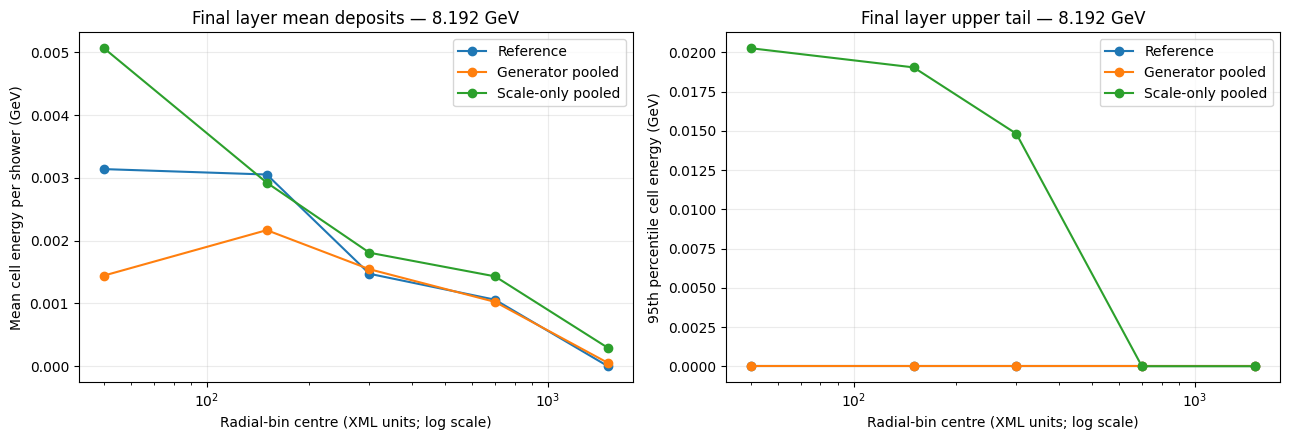

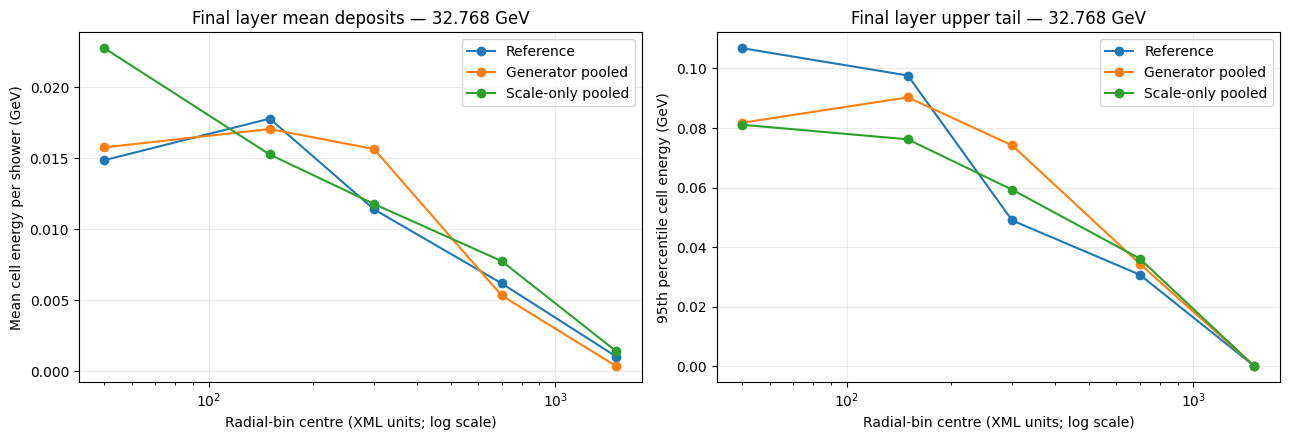

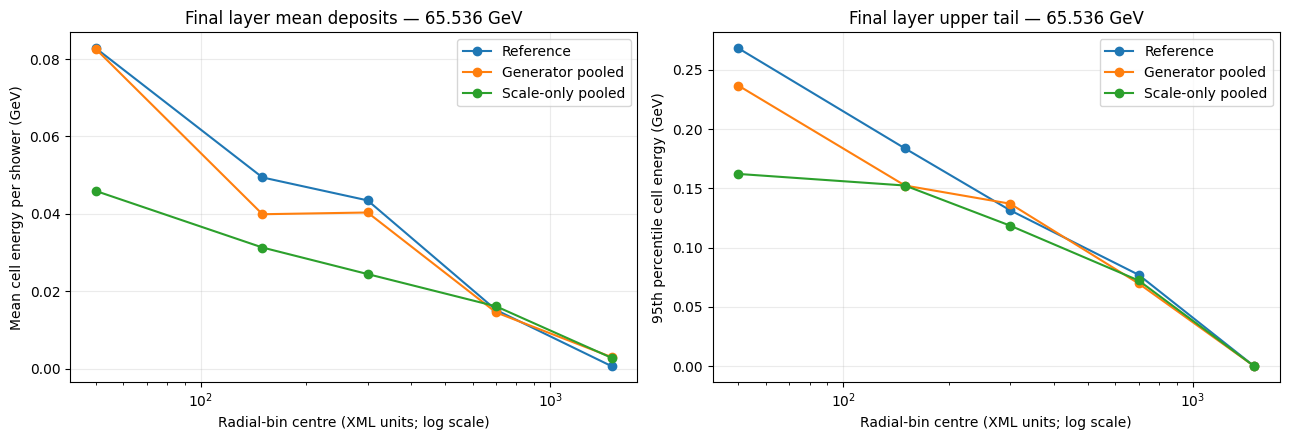

In [8]:
plot_groups = [
    ('reference', f'fixed_{REFERENCE_SEED}', 'Reference'),
    ('generator', 'pooled_3_seeds', 'Generator pooled'),
    ('scale_only', 'pooled_3_seeds', 'Scale-only pooled'),
]

for energy in ENERGIES_GEV:
    subset = radial_profile_df[radial_profile_df.energy_GeV == energy]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for method, seed_label, label in plot_groups:
        s = subset[(subset.method == method) & (subset.seed == seed_label)].sort_values('radial_bin')
        axes[0].plot(s.r_center_XML, s.mean_cell_GeV, marker='o', label=label)
        axes[1].plot(s.r_center_XML, s.q95_cell_GeV, marker='o', label=label)

    for ax in axes:
        ax.set_xscale('log')
        ax.set_xlabel('Radial-bin centre (XML units; log scale)')
        ax.grid(alpha=0.25)
        ax.legend()
    axes[0].set_ylabel('Mean cell energy per shower (GeV)')
    axes[0].set_title(f'Final layer mean deposits — {energy:g} GeV')
    axes[1].set_ylabel('95th percentile cell energy (GeV)')
    axes[1].set_title(f'Final layer upper tail — {energy:g} GeV')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f'final_layer_radial_profile_{energy:.3f}GeV.png', dpi=160)
    plt.show()

## 8. Quantify outer-layer and radial-tail behaviour

This produces event-distribution summaries for final-layer energy fraction, the outermost cell and radial RMS. It also reports how often samples exceed the **fixed-reference 99th-percentile threshold** for each observable. The 99th percentile is based on only 300 reference events, so the threshold is a useful diagnostic, not a precise estimate of a rare physical limit.

**Zero-inflated metric note:** the reference 99th percentile for outermost-cell energy can be exactly zero if almost all reference showers have no deposit there. In that case, the `> reference q99` rate is effectively the nonzero-hit rate; use the separate ≥0.1 GeV and ≥1 GeV rates to judge the size of deposits.

In [9]:
tail_rows = []
threshold_rows = []

for energy in ENERGIES_GEV:
    ref = populations[(energy, 'reference', f'fixed_{REFERENCE_SEED}')]['events']
    metrics = ['response', 'final_layer_fraction', 'outermost_cell_GeV', 'r_rms_XML']
    ref_q99 = {metric: float(ref[metric].quantile(0.99)) for metric in metrics}
    ref_max = {metric: float(ref[metric].max()) for metric in metrics}

    for method, seed_label in sample_keys:
        ev = populations[(energy, method, seed_label)]['events']
        tail_rows.append({
            'energy_GeV': energy,
            'method': method,
            'seed': seed_label,
            'n': len(ev),
            'final_layer_fraction_median': ev.final_layer_fraction.median(),
            'final_layer_fraction_q95': ev.final_layer_fraction.quantile(0.95),
            'final_layer_fraction_q99': ev.final_layer_fraction.quantile(0.99),
            'final_layer_fraction_max': ev.final_layer_fraction.max(),
            'outer_cell_hit_rate': (ev.outermost_cell_GeV > 0).mean(),
            'outer_cell_rate_ge_0p1_GeV': (ev.outermost_cell_GeV >= 0.1).mean(),
            'outer_cell_rate_ge_1_GeV': (ev.outermost_cell_GeV >= 1.0).mean(),
            'outer_cell_q95_GeV': ev.outermost_cell_GeV.quantile(0.95),
            'outer_cell_q99_GeV': ev.outermost_cell_GeV.quantile(0.99),
            'outer_cell_max_GeV': ev.outermost_cell_GeV.max(),
            'r_rms_q95_XML': ev.r_rms_XML.quantile(0.95),
            'r_rms_q99_XML': ev.r_rms_XML.quantile(0.99),
            'r_rms_max_XML': ev.r_rms_XML.max(),
        })
        if method != 'reference':
            for metric in metrics:
                threshold = ref_q99[metric]
                rate = float((ev[metric] > threshold).mean())
                count = int((ev[metric] > threshold).sum())
                threshold_rows.append({
                    'energy_GeV': energy,
                    'method': method,
                    'seed': seed_label,
                    'metric': metric,
                    'reference_q99_threshold': threshold,
                    'reference_max': ref_max[metric],
                    'n': len(ev),
                    'n_above_reference_q99': count,
                    'fraction_above_reference_q99': rate,
                })

tail_summary_df = pd.DataFrame(tail_rows)
q99_exceedance_df = pd.DataFrame(threshold_rows)

print('Outer-layer and radial-tail summary at 65.536 GeV:')
display(tail_summary_df[
    (tail_summary_df.energy_GeV == 65.536) &
    (tail_summary_df.seed.isin([f'fixed_{REFERENCE_SEED}', 'pooled_3_seeds']))
].round(5))

print('Generated and scale-only exceedance rates relative to fixed-reference q99:')
display(q99_exceedance_df[
    (q99_exceedance_df.energy_GeV == 65.536) &
    (q99_exceedance_df.seed == 'pooled_3_seeds')
].round(5))

Outer-layer and radial-tail summary at 65.536 GeV:


,energy_GeV,method,seed,n,final_layer_fraction_median,final_layer_fraction_q95,final_layer_fraction_q99,final_layer_fraction_max,outer_cell_hit_rate,outer_cell_rate_ge_0p1_GeV,outer_cell_rate_ge_1_GeV,outer_cell_q95_GeV,outer_cell_q99_GeV,outer_cell_max_GeV,r_rms_q95_XML,r_rms_q99_XML,r_rms_max_XML
18,65.536,reference,fixed_20261020,300,0.00130,0.00818,0.02952,0.18018,0.02000,0.00000,0.00000,0.0,0.01894,0.09881,44.90928,56.56592,84.30944
25,65.536,generator,pooled_3_seeds,1800,0.00126,0.00696,0.01436,0.57915,0.01556,0.00167,0.00056,0.0,0.01936,4.09790,43.40209,53.36784,416.30402
26,65.536,scale_only,pooled_3_seeds,900,0.00072,0.00550,0.01433,0.19888,0.02111,0.00778,0.00000,0.0,0.07924,0.56022,45.76190,94.66691,148.00539


Generated and scale-only exceedance rates relative to fixed-reference q99:


,energy_GeV,method,seed,metric,reference_q99_threshold,reference_max,n,n_above_reference_q99,fraction_above_reference_q99
88,65.536,generator,pooled_3_seeds,response,0.99478,0.99955,1800,141,0.07833
89,65.536,generator,pooled_3_seeds,final_layer_fraction,0.02952,0.18018,1800,8,0.00444
90,65.536,generator,pooled_3_seeds,outermost_cell_GeV,0.01894,0.09881,1800,19,0.01056
91,65.536,generator,pooled_3_seeds,r_rms_XML,56.56592,84.30944,1800,14,0.00778
92,65.536,scale_only,pooled_3_seeds,response,0.99478,0.99955,900,56,0.06222
93,65.536,scale_only,pooled_3_seeds,final_layer_fraction,0.02952,0.18018,900,3,0.00333
94,65.536,scale_only,pooled_3_seeds,outermost_cell_GeV,0.01894,0.09881,900,18,0.02000
95,65.536,scale_only,pooled_3_seeds,r_rms_XML,56.56592,84.30944,900,21,0.02333


## 9. Find and inspect three candidate anomalous showers automatically

Rather than hard-coding event IDs, the notebook selects: (A) the generated 65.536 GeV shower with the largest radial RMS, (B) the generated 65.536 GeV shower with the highest response, and (C) the generated 32.768 GeV shower with the lowest response. These are diagnostic candidates, not automatically physical failures.

The candidate selection is performed from the arrays at runtime. This avoids relying on manually typed event labels; the lowest-response 32.768 GeV candidate in the supplied files is expected to be found in seed `20261022`, generation repeat 1, row 51.

In [10]:
generator_events = event_level[event_level.method == 'generator'].copy()

candidate_specs = [
    ('A_extreme_radial_65p536', 65.536, 'r_rms_XML', 'max'),
    ('B_high_response_65p536', 65.536, 'response', 'max'),
    ('C_low_response_32p768', 32.768, 'response', 'min'),
]

candidate_rows = []
for label, energy, metric, direction in candidate_specs:
    subset = generator_events[generator_events.energy_GeV == energy]
    idx = subset[metric].idxmax() if direction == 'max' else subset[metric].idxmin()
    row = subset.loc[idx].copy()
    row['candidate_label'] = label
    row['selection_metric'] = metric
    row['selection_direction'] = direction
    candidate_rows.append(row)

candidates_df = pd.DataFrame(candidate_rows).reset_index(drop=True)
cols = [
    'candidate_label','energy_GeV','seed','generation_run','row_index','event_id',
    'incident_GeV','deposited_GeV','response','r_rms_XML',
    'final_layer_GeV','final_layer_fraction','outermost_cell_GeV','outermost_cell_fraction'
]
print('Automatically selected candidate showers:')
display(candidates_df[cols].round(6))

Automatically selected candidate showers:


,candidate_label,energy_GeV,seed,generation_run,row_index,event_id,incident_GeV,deposited_GeV,response,r_rms_XML,final_layer_GeV,final_layer_fraction,outermost_cell_GeV,outermost_cell_fraction
0,A_extreme_radial_65p536,65.536,20261021,0,161,gen:photon:65.536GeV:0:161,65.536,59.552852,0.908704,416.304024,14.997795,0.251840,4.097897,0.068811
1,B_high_response_65p536,65.536,20261021,0,56,gen:photon:65.536GeV:0:56,65.536,73.032461,1.114387,141.035639,42.296548,0.579147,0.000000,0.000000
2,C_low_response_32p768,32.768,20261022,1,51,gen:photon:32.768GeV:1:51,32.768,14.020712,0.427878,180.292748,5.998917,0.427861,0.020489,0.001461


## 10. Compare anomalous showers layer-by-layer

For each candidate, compare its energy in each active layer with the fixed reference distribution and the pooled generator/scale-only distributions at the same incident energy. Layer position is shown as active-layer ordinal because these files do not contain physical layer z-centres.

,candidate_label,event_id,energy_GeV,layer_ordinal,layer_id,candidate_layer_GeV,reference_median_GeV,reference_q05_GeV,reference_q95_GeV,generator_pooled_median_GeV,scale_only_pooled_median_GeV
0,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,0,0,0.40945,0.25890,0.00000,1.48265,0.27308,0.43826
1,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,1,1,9.74645,10.83585,0.90707,20.68465,11.34962,14.96745
2,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,2,2,33.38805,52.05898,40.91513,61.30816,51.42073,47.82272
3,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,3,3,1.01111,0.21174,0.07502,0.61448,0.20558,0.14286
4,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,4,12,14.99780,0.08311,0.00000,0.52796,0.07953,0.04650
5,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,0,0,0.58119,0.25890,0.00000,1.48265,0.27308,0.43826
6,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,1,1,6.54275,10.83585,0.90707,20.68465,11.34962,14.96745
7,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,2,2,22.99068,52.05898,40.91513,61.30816,51.42073,47.82272
8,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,3,3,0.62130,0.21174,0.07502,0.61448,0.20558,0.14286
9,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,4,12,42.29655,0.08311,0.00000,0.52796,0.07953,0.04650


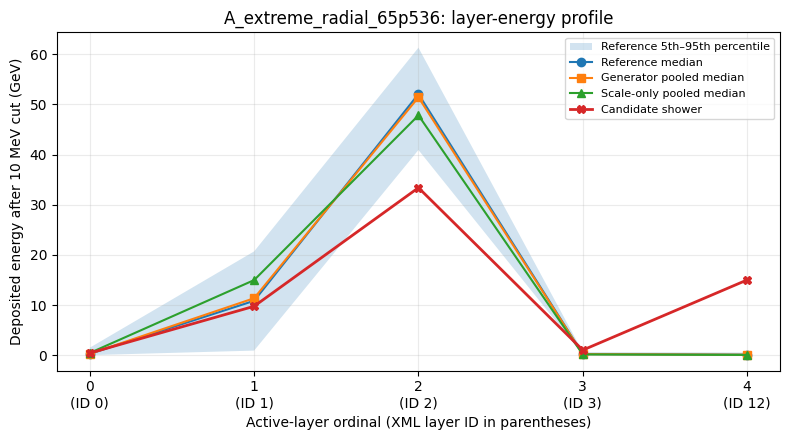

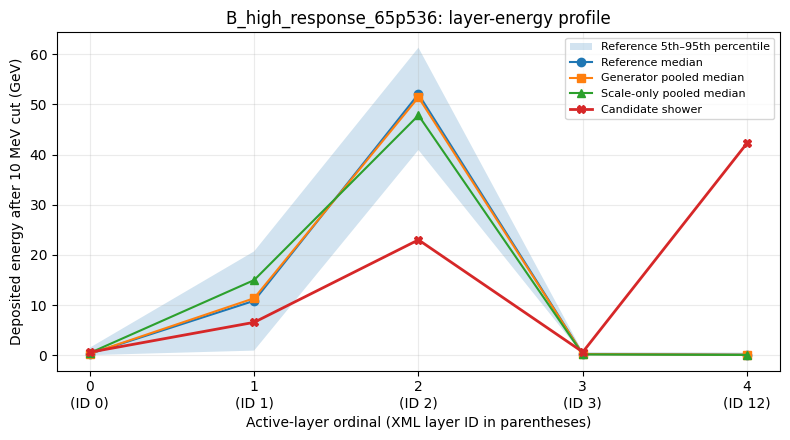

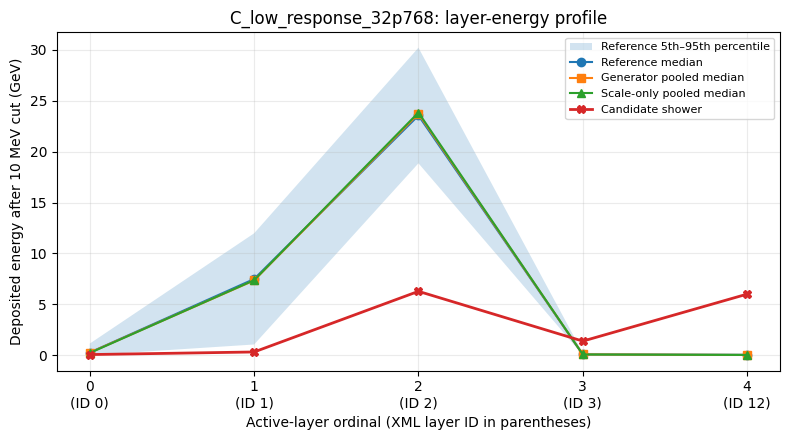

In [11]:
profile_rows = []
for candidate in candidates_df.itertuples():
    energy = float(candidate.energy_GeV)
    cand_event = event_level[
        (event_level.method == 'generator') &
        (event_level.seed == str(candidate.seed)) &
        (event_level.generation_run == int(candidate.generation_run)) &
        (event_level.row_index == int(candidate.row_index)) &
        (event_level.energy_GeV == energy)
    ].iloc[0]

    for layer in layer_rows:
        lid = int(layer['layer_id'])
        col = f'layer_{lid}_GeV'
        ref_ev = populations[(energy, 'reference', f'fixed_{REFERENCE_SEED}')]['events'][col]
        gen_ev = populations[(energy, 'generator', 'pooled_3_seeds')]['events'][col]
        scale_ev = populations[(energy, 'scale_only', 'pooled_3_seeds')]['events'][col]
        profile_rows.append({
            'candidate_label': candidate.candidate_label,
            'event_id': candidate.event_id,
            'energy_GeV': energy,
            'layer_ordinal': int(layer['layer_ordinal']),
            'layer_id': lid,
            'candidate_layer_GeV': float(cand_event[col]),
            'reference_median_GeV': float(ref_ev.median()),
            'reference_q05_GeV': float(ref_ev.quantile(0.05)),
            'reference_q95_GeV': float(ref_ev.quantile(0.95)),
            'generator_pooled_median_GeV': float(gen_ev.median()),
            'scale_only_pooled_median_GeV': float(scale_ev.median()),
        })

layer_profiles_df = pd.DataFrame(profile_rows)
display(layer_profiles_df.round(5))

for label in candidates_df['candidate_label']:
    s = layer_profiles_df[layer_profiles_df.candidate_label == label].sort_values('layer_ordinal')
    x = s.layer_ordinal.to_numpy()
    y = s.candidate_layer_GeV.to_numpy()
    ref_med = s.reference_median_GeV.to_numpy()
    ref_lo = s.reference_q05_GeV.to_numpy()
    ref_hi = s.reference_q95_GeV.to_numpy()
    plt.figure(figsize=(8, 4.5))
    plt.fill_between(x, ref_lo, ref_hi, alpha=0.2, label='Reference 5th–95th percentile')
    plt.plot(x, ref_med, marker='o', label='Reference median')
    plt.plot(x, s.generator_pooled_median_GeV, marker='s', label='Generator pooled median')
    plt.plot(x, s.scale_only_pooled_median_GeV, marker='^', label='Scale-only pooled median')
    plt.plot(x, y, marker='X', linewidth=2, label='Candidate shower')
    plt.xticks(x, [f"{int(o)}\n(ID {int(l)})" for o,l in zip(s.layer_ordinal,s.layer_id)])
    plt.xlabel('Active-layer ordinal (XML layer ID in parentheses)')
    plt.ylabel('Deposited energy after 10 MeV cut (GeV)')
    plt.title(f'{label}: layer-energy profile')
    plt.grid(alpha=0.25)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{label}_layer_profile.png', dpi=160)
    plt.show()

## 11. Inspect cell-by-cell deposits for the candidate events

This exports every native cell for each candidate, including layer, angular bin, radial bin and the deposit before/after the 10 MeV cut. For the two 65.536 GeV candidates, the final-layer radial bins are plotted explicitly.


 A_extreme_radial_65p536 | gen:photon:65.536GeV:0:161


,native_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,energy_raw_GeV,energy_after_cut_GeV,fraction_of_total_kept
363,363,12,0,0,0.0,100.0,6.033397,6.033397,0.101312
364,364,12,0,1,100.0,200.0,1.530282,1.530282,0.025696
365,365,12,0,2,200.0,400.0,1.819340,1.819340,0.030550
366,366,12,0,3,400.0,1000.0,1.516879,1.516879,0.025471
367,367,12,0,4,1000.0,2000.0,4.097897,4.097897,0.068811


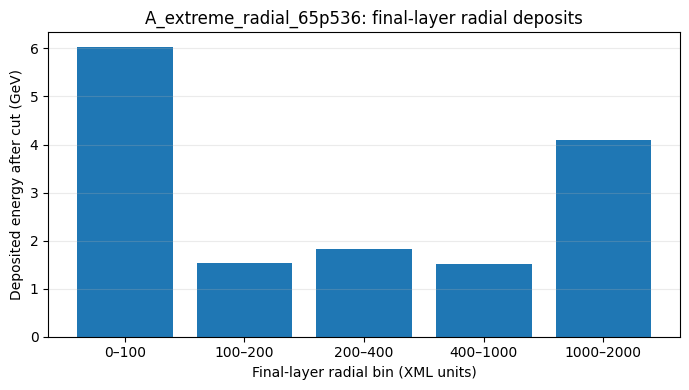


 B_high_response_65p536 | gen:photon:65.536GeV:0:56


,native_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,energy_raw_GeV,energy_after_cut_GeV,fraction_of_total_kept
731,363,12,0,0,0.0,100.0,30.562286,30.562286,0.418475
732,364,12,0,1,100.0,200.0,0.632014,0.632014,0.008654
733,365,12,0,2,200.0,400.0,10.486157,10.486157,0.143582
734,366,12,0,3,400.0,1000.0,0.616090,0.616090,0.008436
735,367,12,0,4,1000.0,2000.0,0.000527,0.000000,0.000000


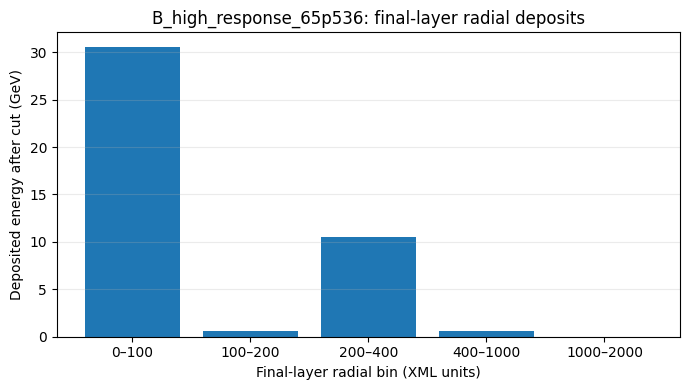


 C_low_response_32p768 | gen:photon:32.768GeV:1:51


,native_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,energy_raw_GeV,energy_after_cut_GeV,fraction_of_total_kept
1099,363,12,0,0,0.0,100.0,1.168582,1.168582,0.083347
1100,364,12,0,1,100.0,200.0,3.271852,3.271852,0.233358
1101,365,12,0,2,200.0,400.0,1.463015,1.463015,0.104347
1102,366,12,0,3,400.0,1000.0,0.074980,0.074980,0.005348
1103,367,12,0,4,1000.0,2000.0,0.020489,0.020489,0.001461


In [12]:
candidate_cell_frames = []
for candidate in candidates_df.itertuples():
    seed = int(candidate.seed)
    energy = float(candidate.energy_GeV)
    run_number = int(candidate.generation_run)
    row_index = int(candidate.row_index)
    raw_data = runs[seed]['data'][energy][f'generator_run{run_number}']
    raw_native = raw_data['native'][row_index].astype(float)
    kept_native = apply_cell_cut(raw_native)
    total_kept = kept_native.sum()

    temp = cell_map.copy()
    temp['candidate_label'] = candidate.candidate_label
    temp['event_id'] = candidate.event_id
    temp['energy_GeV'] = energy
    temp['seed'] = seed
    temp['generation_run'] = run_number
    temp['energy_raw_GeV'] = raw_native
    temp['energy_after_cut_GeV'] = kept_native
    temp['fraction_of_total_kept'] = kept_native / total_kept if total_kept > 0 else 0.0
    candidate_cell_frames.append(temp)

candidate_cells_df = pd.concat(candidate_cell_frames, ignore_index=True)

for candidate in candidates_df.itertuples():
    s = candidate_cells_df[candidate_cells_df.candidate_label == candidate.candidate_label]
    final = s[s.layer_id == final_layer_id].sort_values('radial_bin')
    print('\n', candidate.candidate_label, '|', candidate.event_id)
    display(final[[
        'native_index','layer_id','angle_index','radial_bin',
        'r_low_XML','r_high_XML','energy_raw_GeV','energy_after_cut_GeV',
        'fraction_of_total_kept'
    ]].round(6))

    if float(candidate.energy_GeV) == 65.536:
        plt.figure(figsize=(7,4))
        plt.bar(
            [f"{int(a)}–{int(b)}" for a,b in zip(final.r_low_XML, final.r_high_XML)],
            final.energy_after_cut_GeV
        )
        plt.xlabel('Final-layer radial bin (XML units)')
        plt.ylabel('Deposited energy after cut (GeV)')
        plt.title(f'{candidate.candidate_label}: final-layer radial deposits')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f'{candidate.candidate_label}_final_layer_radial.png', dpi=160)
        plt.show()

## 12. Final response statistics

For every incident energy, the table reports the mean, standard deviation, lower and upper percentiles, and maximum response for the fixed reference, each seed, and pooled samples. Pooled results are descriptive; inspect the seed-level rows for reproducibility.

In [13]:
def response_summary(native, incident):
    total = native.sum(axis=1)
    r = total / np.asarray(incident, dtype=float)
    return {
        'n': len(r),
        'mean': float(np.mean(r)),
        'std': float(np.std(r, ddof=1)),
        'q05': float(np.quantile(r, 0.05)),
        'q50': float(np.quantile(r, 0.50)),
        'q90': float(np.quantile(r, 0.90)),
        'q95': float(np.quantile(r, 0.95)),
        'q99': float(np.quantile(r, 0.99)),
        'min': float(np.min(r)),
        'max': float(np.max(r)),
    }

response_rows = []
for energy in ENERGIES_GEV:
    for method, seed_label in sample_keys:
        pop = populations[(energy, method, seed_label)]
        response_rows.append({
            'energy_GeV': energy,
            'method': method,
            'seed': seed_label,
            **response_summary(pop['native'], pop['incident'])
        })

response_stats_df = pd.DataFrame(response_rows)
print('Response mean, spread and tails:')
display(response_stats_df.round(6))

Response mean, spread and tails:


,energy_GeV,method,seed,n,mean,std,q05,q50,q90,q95,q99,min,max
0,8.192,reference,fixed_20261020,300,0.924469,0.031297,0.873335,0.925321,0.964083,0.974853,0.987676,0.834189,0.997924
1,8.192,generator,20261020,600,0.917316,0.037788,0.860632,0.916779,0.964173,0.980735,1.007065,0.792001,1.051860
2,8.192,scale_only,20261020,300,0.914712,0.018410,0.888212,0.913648,0.937106,0.943750,0.962891,0.845967,0.982396
3,8.192,generator,20261021,600,0.917406,0.037482,0.856460,0.917540,0.962889,0.979083,1.004766,0.808441,1.056009
4,8.192,scale_only,20261021,300,0.913543,0.021465,0.885761,0.913722,0.935157,0.943750,0.958640,0.739447,0.982396
5,8.192,generator,20261022,600,0.914054,0.037304,0.850831,0.915852,0.961671,0.975773,1.001749,0.789475,1.032543
6,8.192,scale_only,20261022,300,0.913081,0.019975,0.886544,0.912765,0.935031,0.943459,0.957170,0.739447,0.975411
7,8.192,generator,pooled_3_seeds,1800,0.916259,0.037537,0.854727,0.916382,0.963200,0.979083,1.004770,0.789475,1.056009
8,8.192,scale_only,pooled_3_seeds,900,0.913779,0.019978,0.886404,0.913591,0.935852,0.943731,0.957809,0.739447,0.982396
9,32.768,reference,fixed_20261020,300,0.966165,0.015022,0.943317,0.966564,0.984418,0.991660,0.998857,0.876154,1.009136


## 13. Wasserstein comparison and bootstrap uncertainty

Wasserstein distance (W1) compares two full one-dimensional distributions; lower is closer. For each seed and energy, the generator and scale-only samples are compared against the same fixed reference. The bootstrap resamples the reference once per replicate and independently resamples generator and scale-only events.

Interpretation of `delta_W1 = W1_generator - W1_scale_only`:
- Entire 95% interval above zero: scale-only is closer in this comparison.
- Entire interval below zero: generator is closer.
- Interval crosses zero: inconclusive at this bootstrap resolution.

These are exploratory intervals and are not adjusted for the multiple energy/seed comparisons.

In [14]:
def response_values(pop):
    return pop['native'].sum(axis=1) / pop['incident']

def bootstrap_w1_difference(reference, generator, scale_only, n_boot=N_BOOTSTRAP, seed=BOOTSTRAP_SEED):
    rng = np.random.default_rng(seed)
    point_gen = wasserstein_distance(reference, generator)
    point_scale = wasserstein_distance(reference, scale_only)
    point_delta = point_gen - point_scale
    deltas = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        r = rng.choice(reference, size=len(reference), replace=True)
        g = rng.choice(generator, size=len(generator), replace=True)
        s = rng.choice(scale_only, size=len(scale_only), replace=True)
        deltas[b] = wasserstein_distance(r, g) - wasserstein_distance(r, s)

    lo, hi = np.quantile(deltas, [0.025, 0.975])
    if lo > 0:
        conclusion = 'scale-only closer (interval above 0)'
    elif hi < 0:
        conclusion = 'generator closer (interval below 0)'
    else:
        conclusion = 'inconclusive (interval includes 0)'
    return point_gen, point_scale, point_delta, float(lo), float(hi), conclusion

w1_rows = []
for energy in ENERGIES_GEV:
    ref_pop = populations[(energy, 'reference', f'fixed_{REFERENCE_SEED}')]
    ref_r = response_values(ref_pop)

    for seed in EXPECTED_SEEDS:
        gen_r = response_values(populations[(energy, 'generator', str(seed))])
        scale_r = response_values(populations[(energy, 'scale_only', str(seed))])
        out = bootstrap_w1_difference(
            ref_r, gen_r, scale_r,
            seed=BOOTSTRAP_SEED + int(round(energy * 1000)) + seed
        )
        w1_rows.append({
            'energy_GeV': energy,
            'seed': seed,
            'n_reference': len(ref_r),
            'n_generator': len(gen_r),
            'n_scale_only': len(scale_r),
            'W1_generator': out[0],
            'W1_scale_only': out[1],
            'delta_W1_gen_minus_scale': out[2],
            'delta_W1_CI95_low': out[3],
            'delta_W1_CI95_high': out[4],
            'interpretation': out[5],
        })

    # Pooled W1 is descriptive only; no pooled-seed bootstrap is used here.
    gen_pool = response_values(populations[(energy, 'generator', 'pooled_3_seeds')])
    scale_pool = response_values(populations[(energy, 'scale_only', 'pooled_3_seeds')])
    w1_rows.append({
        'energy_GeV': energy,
        'seed': 'pooled_3_seeds',
        'n_reference': len(ref_r),
        'n_generator': len(gen_pool),
        'n_scale_only': len(scale_pool),
        'W1_generator': wasserstein_distance(ref_r, gen_pool),
        'W1_scale_only': wasserstein_distance(ref_r, scale_pool),
        'delta_W1_gen_minus_scale': wasserstein_distance(ref_r, gen_pool) - wasserstein_distance(ref_r, scale_pool),
        'delta_W1_CI95_low': np.nan,
        'delta_W1_CI95_high': np.nan,
        'interpretation': 'descriptive pooled comparison; no CI',
    })

w1_df = pd.DataFrame(w1_rows)
print('Seed-by-seed W1 and bootstrap intervals:')
display(w1_df.round(6))

Seed-by-seed W1 and bootstrap intervals:


,energy_GeV,seed,n_reference,n_generator,n_scale_only,W1_generator,W1_scale_only,delta_W1_gen_minus_scale,delta_W1_CI95_low,delta_W1_CI95_high,interpretation
0,8.192,20261020,300,600,300,0.008803,0.014158,-0.005355,-0.009159,-0.001228,generator closer (interval below 0)
1,8.192,20261021,300,600,300,0.008663,0.014631,-0.005968,-0.009692,-0.002023,generator closer (interval below 0)
2,8.192,20261022,300,600,300,0.011432,0.015224,-0.003792,-0.007652,-0.000060,generator closer (interval below 0)
3,8.192,pooled_3_seeds,300,1800,900,0.009600,0.014647,-0.005047,NaN,NaN,descriptive pooled comparison; no CI
4,32.768,20261020,300,600,300,0.006039,0.001672,0.004367,0.001150,0.005939,scale-only closer (interval above 0)
5,32.768,20261021,300,600,300,0.006720,0.002372,0.004348,0.001554,0.006328,scale-only closer (interval above 0)
6,32.768,20261022,300,600,300,0.006812,0.001101,0.005711,0.002439,0.007508,scale-only closer (interval above 0)
7,32.768,pooled_3_seeds,300,1800,900,0.006451,0.001544,0.004907,NaN,NaN,descriptive pooled comparison; no CI
8,65.536,20261020,300,600,300,0.007034,0.003338,0.003697,0.001475,0.005342,scale-only closer (interval above 0)
9,65.536,20261021,300,600,300,0.007672,0.002963,0.004709,0.002199,0.005745,scale-only closer (interval above 0)


## 14. Plot response distributions

Empirical cumulative distribution functions (ECDFs) display the complete response distributions. They make shifts, widths and tails visible without depending on histogram bin choices.

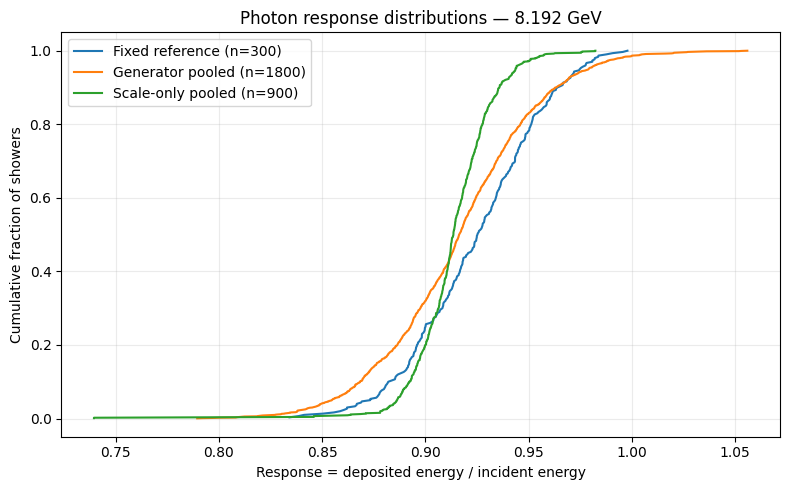

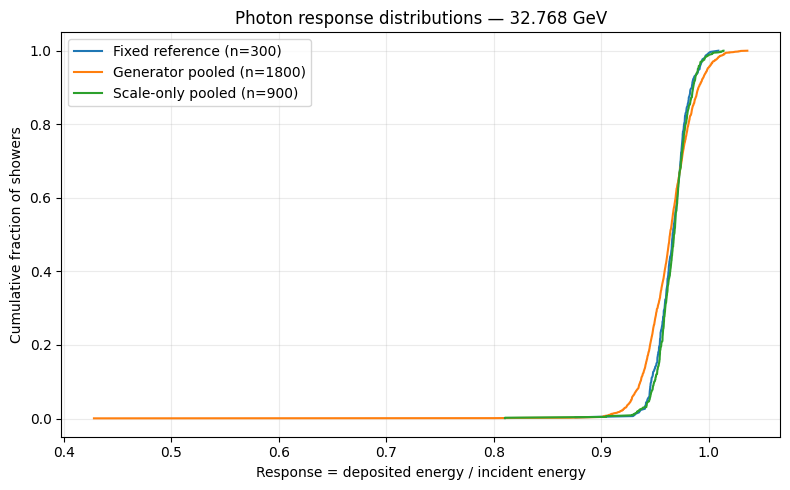

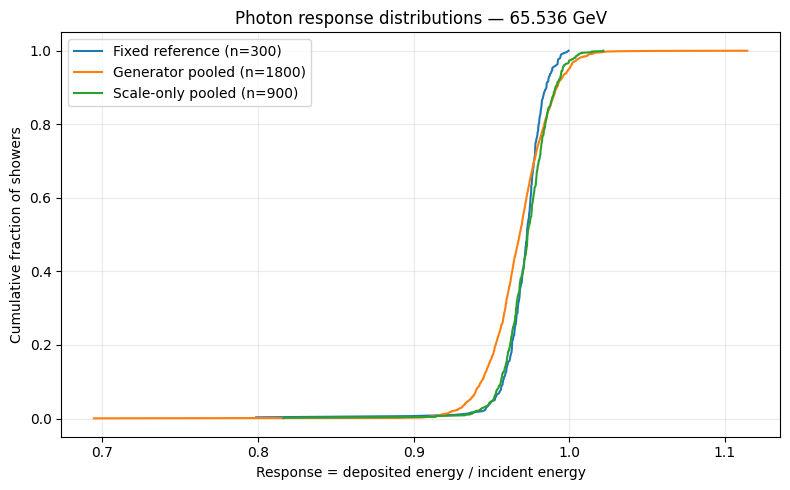

In [15]:
for energy in ENERGIES_GEV:
    plt.figure(figsize=(8, 5))
    for method, seed_label, label in [
        ('reference', f'fixed_{REFERENCE_SEED}', 'Fixed reference (n=300)'),
        ('generator', 'pooled_3_seeds', 'Generator pooled (n=1800)'),
        ('scale_only', 'pooled_3_seeds', 'Scale-only pooled (n=900)'),
    ]:
        r = response_values(populations[(energy, method, seed_label)])
        x = np.sort(r)
        y = np.arange(1, len(x) + 1) / len(x)
        plt.plot(x, y, label=label)
    plt.xlabel('Response = deposited energy / incident energy')
    plt.ylabel('Cumulative fraction of showers')
    plt.title(f'Photon response distributions — {energy:g} GeV')
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'response_ecdf_{energy:.3f}GeV.png', dpi=160)
    plt.show()

## 15. Compare selected showers with reference quantiles

This table checks how exceptional each candidate is relative to the 300-event fixed reference sample at the same energy. `above_reference_max` is a descriptive flag: reference maxima from 300 events are not physical upper limits.

In [16]:
candidate_comparison_rows = []
for candidate in candidates_df.itertuples():
    energy = float(candidate.energy_GeV)
    ref = populations[(energy, 'reference', f'fixed_{REFERENCE_SEED}')]['events']
    row = {
        'candidate_label': candidate.candidate_label,
        'event_id': candidate.event_id,
        'energy_GeV': energy,
        'seed': int(candidate.seed),
        'generation_run': int(candidate.generation_run),
    }
    for metric in ['response', 'r_rms_XML', 'final_layer_fraction', 'outermost_cell_GeV']:
        value = float(getattr(candidate, metric))
        row[f'{metric}_value'] = value
        row[f'{metric}_reference_q95'] = float(ref[metric].quantile(0.95))
        row[f'{metric}_reference_q99'] = float(ref[metric].quantile(0.99))
        row[f'{metric}_reference_max'] = float(ref[metric].max())
        row[f'{metric}_above_reference_max'] = bool(value > ref[metric].max())
    candidate_comparison_rows.append(row)

candidate_comparison_df = pd.DataFrame(candidate_comparison_rows)
display(candidate_comparison_df.round(6))

,candidate_label,event_id,energy_GeV,seed,generation_run,response_value,response_reference_q95,response_reference_q99,response_reference_max,response_above_reference_max,...,final_layer_fraction_value,final_layer_fraction_reference_q95,final_layer_fraction_reference_q99,final_layer_fraction_reference_max,final_layer_fraction_above_reference_max,outermost_cell_GeV_value,outermost_cell_GeV_reference_q95,outermost_cell_GeV_reference_q99,outermost_cell_GeV_reference_max,outermost_cell_GeV_above_reference_max
0,A_extreme_radial_65p536,gen:photon:65.536GeV:0:161,65.536,20261021,0,0.908704,0.98904,0.994782,0.999548,False,...,0.251840,0.008177,0.029523,0.180184,True,4.097897,0.0,0.018936,0.098814,True
1,B_high_response_65p536,gen:photon:65.536GeV:0:56,65.536,20261021,0,1.114387,0.98904,0.994782,0.999548,True,...,0.579147,0.008177,0.029523,0.180184,True,0.000000,0.0,0.018936,0.098814,False
2,C_low_response_32p768,gen:photon:32.768GeV:1:51,32.768,20261022,1,0.427878,0.99166,0.998857,1.009136,False,...,0.427861,0.005888,0.011948,0.065474,True,0.020489,0.0,0.041955,0.104163,False


## 16. Interpret the outputs carefully

Use these rules when reading the tables:

- A higher final-layer fraction means more of that shower's retained energy is in the deepest active layer.
- A large outermost-cell deposit is a spatial-tail candidate, but it is not automatically unphysical.
- A high radial RMS can be driven by one or a few far-out deposits. Compare its 95th/99th percentiles and maximum, not just the maximum.
- A broader response distribution means a larger standard deviation and/or wider percentiles. A small mean shift alone does not describe the full mismatch.
- A lower W1 means the response distribution is closer to the reference. The scale-only baseline is not a complete competing shower model; this notebook evaluates its response distribution and final-layer radial deposits only.
- The 99th percentile from 300 reference events is determined by very few events. Treat q99 and maxima cautiously.
- Pooled generator events combine three seeds; always inspect the individual seed rows as well.
- The reference/checkpoint independence flag remains unresolved in the run manifests.


## 17. Photon closeout checklist and readiness for electrons

This final cell checks whether the remaining photon diagnostics were produced. It does not declare the model physically correct. Once the outputs have been reviewed and any anomalies are documented, the same validation framework can be applied to electrons. Reference/checkpoint independence must remain an explicit caveat until confirmed by the data provider or guide.

In [17]:
closeout_items = [
    ('Native cell ordering', 'Verified in the separate native-ordering notebook; 368 cells and index 367 mapping checked.'),
    ('Final-layer radial-bin comparison', 'This notebook: five bins compared across reference, generator and scale-only.'),
    ('Outer-layer tail frequencies', 'This notebook: hit rates, fixed-threshold rates and reference-q99 exceedances.'),
    ('Candidate anomalous showers', 'This notebook: radial extreme, high-response and low-response candidates selected automatically.'),
    ('Layer-profile comparison', 'This notebook: candidate profiles compared with reference/generator/scale-only distributions.'),
    ('Response summary', 'This notebook: mean, standard deviation, percentiles and ECDFs.'),
    ('Response W1 uncertainty', 'This notebook: per-seed bootstrap intervals for generator-minus-scale-only W1.'),
    ('Reference independence from checkpoint', 'NOT RESOLVED: manifests report reference_is_unseen_by_checkpoint = false.'),
]
closeout_df = pd.DataFrame(closeout_items, columns=['item','status_or_note'])
display(closeout_df)

print('\nSuggested decision:')
print('- The photon diagnostic work is ready for review once all tables and plots have been inspected.')
print('- If no array-integrity or geometry mismatch appears, proceed to the same validation for electrons.')
print('- Keep reference/checkpoint independence as an explicit limitation; do not claim an independent benchmark yet.')

,item,status_or_note
0,Native cell ordering,Verified in the separate native-ordering noteb...
1,Final-layer radial-bin comparison,This notebook: five bins compared across refer...
2,Outer-layer tail frequencies,"This notebook: hit rates, fixed-threshold rate..."
3,Candidate anomalous showers,"This notebook: radial extreme, high-response a..."
4,Layer-profile comparison,This notebook: candidate profiles compared wit...
5,Response summary,"This notebook: mean, standard deviation, perce..."
6,Response W1 uncertainty,This notebook: per-seed bootstrap intervals fo...
7,Reference independence from checkpoint,NOT RESOLVED: manifests report reference_is_un...



Suggested decision:
- The photon diagnostic work is ready for review once all tables and plots have been inspected.
- If no array-integrity or geometry mismatch appears, proceed to the same validation for electrons.
- Keep reference/checkpoint independence as an explicit limitation; do not claim an independent benchmark yet.


## 18. Export tables, figures and a short report

This creates one ZIP containing all CSV tables, plots and a machine-readable run summary. Download it and share it for interpretation before moving on.

In [18]:
# Export CSV tables.
compatibility_df.to_csv(OUTPUT_DIR / 'run_compatibility.csv', index=False)
radial_profile_df.to_csv(OUTPUT_DIR / 'final_layer_radial_bins.csv', index=False)
tail_summary_df.to_csv(OUTPUT_DIR / 'outer_layer_tail_summary.csv', index=False)
q99_exceedance_df.to_csv(OUTPUT_DIR / 'reference_q99_exceedance_rates.csv', index=False)
response_stats_df.to_csv(OUTPUT_DIR / 'response_statistics_by_seed.csv', index=False)
w1_df.to_csv(OUTPUT_DIR / 'response_w1_bootstrap_by_seed.csv', index=False)
candidates_df[cols].to_csv(OUTPUT_DIR / 'candidate_anomalous_showers.csv', index=False)
candidate_comparison_df.to_csv(OUTPUT_DIR / 'candidate_vs_reference_quantiles.csv', index=False)
layer_profiles_df.to_csv(OUTPUT_DIR / 'candidate_layer_profiles.csv', index=False)
candidate_cells_df.to_csv(OUTPUT_DIR / 'candidate_native_cell_deposits.csv', index=False)
closeout_df.to_csv(OUTPUT_DIR / 'photon_closeout_checklist.csv', index=False)

run_summary = {
    'seeds': EXPECTED_SEEDS,
    'reference_seed': REFERENCE_SEED,
    'energies_GeV': ENERGIES_GEV,
    'analysis_cut_GeV': ANALYSIS_CUT_GEV,
    'n_reference_per_energy': 300,
    'n_generator_per_seed_per_energy': 600,
    'n_scale_only_per_seed_per_energy': 300,
    'native_cells': int(len(cell_map)),
    'final_layer_id': int(final_layer_id),
    'outermost_native_index': int(outermost_native_index),
    'reference_is_unseen_by_checkpoint': bool(
        compatibility_df['reference_is_unseen_by_checkpoint'].fillna(False).all()
    ),
    'note': 'Pooled results are descriptive; seed-level results are retained. Reference/checkpoint independence is unresolved.'
}
with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump(run_summary, f, indent=2)

report_text = "\n".join([
    "# Photon validation closeout",
    "",
    f"- Seeds: {EXPECTED_SEEDS}",
    f"- Fixed reference seed: {REFERENCE_SEED}",
    f"- Energies (GeV): {ENERGIES_GEV}",
    f"- Per-cell analysis threshold: {ANALYSIS_CUT_GEV} GeV",
    f"- Native cells: {len(cell_map)}",
    f"- Final active layer ID: {final_layer_id}",
    f"- Outermost native index: {outermost_native_index}",
    f"- Reference unseen by checkpoint: {run_summary['reference_is_unseen_by_checkpoint']}",
    "",
    "## Candidate anomalous events",
    "",
    candidates_df[cols].to_string(index=False),
    "",
    "## Caveats",
    "",
    "Reference/checkpoint independence is unresolved. Reference q99/max values are based on 300 events and are not physical upper limits. The scale-only comparison here is limited to response and the listed final-layer diagnostics."
])
(OUTPUT_DIR / 'photon_closeout_report.md').write_text(report_text)

import shutil
zip_path = shutil.make_archive('/content/CaloDiffusion_Photon_Closeout_Results', 'zip', OUTPUT_DIR)
print('Created:', zip_path)
print('Files included:', len(list(OUTPUT_DIR.iterdir())))
files.download(zip_path)

Created: /content/CaloDiffusion_Photon_Closeout_Results.zip
Files included: 24


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>